# Where should a peripheral player wait, and which way should it face?

**Question.** In the geometric race model (`geometric_model_assembly.ipynb`), the peripheral agent starts where trained RL agents waited, facing the way they faced. Those are not necessarily good choices. Where should a peripheral player wait at slice onset, and which way should it face, to score fastest against a central player? And what do the walls it can see explain about the answer?

**Plan**
1. The designed start positions.
2. What the rays see from each position and heading.
3. Choosing the heading, with a check on mirrored positions.
4. Backpedalling into the own trigger without turning.
5. The score map: score per second at every position.
6. Why the score changes between positions.
7. Interpretation and limits.

**Choices and assumptions** (full list in `READMEs/analytical_modelling_notes.md`)
- **Rays, not human vision (user's choice, 2026-10-26).** Both agents sense walls with the RL agents' 7 rays (0, ±18.3, ±36.7, ±55° from the heading; first hit only). This keeps the model consistent with the earlier steps and comparable with the RL agents. Humans see everything across a continuous field of view, so a few degrees of heading matter far less to them than to 7 separate rays. **This analysis should be rerun with a human field of view** (for example `get_wall_visible`, which handles occlusion) before it is applied to human players.
- The start position and heading are design choices, not taken from the agents. The heading is chosen before onset from the agent's own position and the arena layout only, so it uses no information about the trial (user's rule).
- Every heading on the 0.5° grid is scored at every position (user's request). The heading with the highest expected score per second is kept (user's choice).
- The rule is the final Δ rule from the assembly notebook (inference about both walls). Δ is chosen for each position together with the heading, since the agent knows where it stands (Claude's choice). Results at the assembly notebook's Δ of 1.05 s are shown beside it.
- New in the rule (user's request, 2026-10-26). An agent in its own alcove but short of its trigger backpedals into the trigger without turning when its target is its own wall with probability 0.8 or more (an arbitrary value for now; section 4). Walls are known only from experience or inference. Standing on the own trigger at onset without the trial ending is experience that the own wall is unlit. The logged-position results were rebuilt with both.
- The central agent is unchanged: exact centre, random heading, always High. From the centre every heading is equally good before onset, so a random heading is already its best. The backpedal applies only inside an alcove, so never to the central agent.
- Time outside the race is 6.545 s per trial (human social mean). Turning rate 331°/s, closing speed while turning 7.57 units/s and speed 10 units/s, as in the assembly notebook.
- The arena is the same at every alcove and mirror-symmetric about each alcove's centre line, and layouts are uniform over High's wall. So positions on one half of one alcove's sector stand for every alcove and side.

**Modules.** `analysis/start_positions.py` (positions, heading sweep, best heading; tests in `tests/test_start_positions.py`) and `analysis/analytical_race.py` (the race model; tests in `tests/test_analytical_race.py`).

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display

import data_strings
import data_extraction.data_saving as data_saving
import analysis.analytical_race as ar
import analysis.agent_raycast as agent_raycast
import analysis.agent_loser_choice as lc
import analysis.start_positions as sp
import trajectory_analysis.visibility_occlusion as vo

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

RECOMPUTE = False                   # rebuild the cached tables (the position map takes about 7 hours on 12 cores)
BATCH = '260929'
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', BATCH)
CUT = 0.5                           # peripheral below this mean onset centrality
D_FIX = 1.05                        # the assembly notebook's best delta (s)

# colours: walls, agents and regions
C_HIGHW, C_LOWW, C_WALL = '#D62728', '#1F77B4', '#AAAAAA'
C_PERIPH, C_CENTRAL, C_ROUTE_C = '#2a78d6', '#6b6b6b', '#eb6834'
C_REGION = {'alcove, in trigger': '#104281', 'alcove, not in trigger': '#3987e5', 'in front of the wall': '#eda100',
            'wall corner': '#D62728'}

### Load the inputs

The measured rates, the central agent's times, the logged peripheral positions (rebuilt with the backpedal rule) and the position map (every designed position × every 0.5° heading × Δ from 0 to 3.8 s).

In [ ]:
# get the batch split, the logged peripheral positions and headings, and the measured rates
tables = data_saving.load_data(f'model_characterisation_{BATCH}', data_saving.cache_dir)['result']
centrality = tables['slice'].groupby('model')['centrality'].mean()
PERIPHERAL = sorted(centrality[centrality < CUT].index)
CENTRAL = sorted(centrality[centrality >= CUT].index)
race_df = data_saving.load_data(f'race_table_{BATCH}', data_saving.cache_dir)['result']
periph = race_df[race_df['model'].isin(PERIPHERAL)].reset_index(drop=True)
traj = data_saving.cached(f'agent_trajectories_{BATCH}_peripheral',
                          lambda: lc.collect_trajectories(SIM_DATA_FOLDER, PERIPHERAL, verbose=False),
                          recompute=RECOMPUTE, stamp=tuple(PERIPHERAL))
onset = periph.merge(traj[['model', 'trial_num', 'player', 'yaw']], on=['model', 'trial_num', 'player'])
POS = onset[['x', 'z']].to_numpy(float)
HEAD = np.degrees([y[0] for y in onset['yaw']])
alignment = data_saving.cached(f'central_alignment_{BATCH}_central5',
                               lambda: ar.collect_central_alignment(SIM_DATA_FOLDER, CENTRAL[:5], verbose=False),
                               recompute=RECOMPUTE, stamp=(tuple(CENTRAL[:5]), ar.ALIGN_TOL, 'rays', 'v4'))
ROT, CLOSE = ar.rotation_speed(alignment), ar.closing_speed(alignment)
OVERHEAD = ar.human_overhead('social')
CT_INF = ar.central_times_inferred(ROT, CLOSE)

# get the logged-position races (with the backpedal rule) and the designed-position map
races = data_saving.cached(f'periph_ray_races_{BATCH}',
                           lambda: ar.build_races_rays(POS, HEAD, ROT, CLOSE, groups=onset['model'].to_numpy()),
                           recompute=RECOMPUTE,
                           stamp=(tuple(PERIPHERAL), len(POS), round(ROT, 3), round(CLOSE, 3), ar.HEAD_STEP, ar.TRACE_DT,
                                  True, True, 'v10'))
positions = sp.designed_positions()
MAP = data_saving.cached(f'start_position_map_{BATCH}',
                         lambda: sp.build_position_map(positions, ROT, CLOSE, CT_INF),
                         recompute=RECOMPUTE,
                         stamp=('v2', ar.BACKPEDAL_P, round(ROT, 3), round(CLOSE, 3), len(positions), len(ar.heading_grid()), len(sp.DELTAS)))
print(f"{len(positions)} designed positions x {len(MAP['headings'])} headings x {len(MAP['deltas'])} deltas")

agent_trajectories_260929_peripheral: loaded from cache
central_alignment_260929_central5: loaded from cache
human_trial_delays: loaded from cache


periph_ray_races_260929: loaded from cache
start_position_map_260929: loaded from cache
147 designed positions x 720 headings x 77 deltas


In [ ]:
# compute score per second for every position, heading and delta
PS = MAP['periph_trial'] / (OVERHEAD + MAP['race_s'])
CS = MAP['central_trial'] / (OVERHEAD + MAP['race_s'])
PS_HEAD = PS.max(axis=2)                                   # best over delta, per position and heading
J_FIX = int(np.argmin(np.abs(MAP['deltas'] - D_FIX)))
best = sp.best_per_position(MAP, OVERHEAD).join(positions)
best_fix = sp.best_per_position(MAP, OVERHEAD, delta=D_FIX).join(positions)

# get each position's facing-centre heading, and headings relative to it
H = MAP['headings']
H_CENTRE = np.degrees(np.arctan2(-positions['x'], -positions['z'])) % 360
REL = ar._wrap(H[None, :] - H_CENTRE.to_numpy()[:, None])  # positions x headings, degrees from facing centre
best['heading_from_centre'] = ar._wrap(best['heading'] - H_CENTRE)
OFFS = [0, 1, -1, 2, -2, 3, -3, 4]                          # walls from own alcove (+ = clockwise)
OFF_ROW = [o % 8 for o in OFFS]                             # alcove 0 is wall row 0


def walls_label(walls):
    """ Return the walls sensed as offsets from own alcove, e.g. '0, +1, +2, -2'. Takes wall row indices. """

    offs = sorted((int(ar.signed_offset(w)) for w in walls), key=OFFS.index)
    return ', '.join(f'{o:+d}' if o not in (0, 4) else str(o) for o in offs)


# name a few positions that stand for each region
NAMED = {'back, centre line': (19.7, 0.0), 'back corner': (19.7, 1.85), 'alcove middle': (18.0, 0.0),
         'alcove mouth': (17.0, 0.0), 'just outside the lip': (16.5, 0.0), 'in front, 2.5 units out': (14.0, 0.0),
         'along the wall face': (ar.W - sp.EDGE, 4.4), 'wall corner': None}
named_idx = {}
for name, pq in NAMED.items():
    if pq is None:
        named_idx[name] = int(positions.index[positions['region'] == 'wall corner'][0])
    else:
        named_idx[name] = int(np.argmin((positions['p'] - pq[0]) ** 2 + (positions['q'] - pq[1]) ** 2))
NAMED_I = list(named_idx.values())


# drawing helpers
WALL_SEGS = vo.get_wall_segments()
WALL_IDS = np.repeat(np.arange(ar.NUM_WALLS), 5)


def draw_arena(ax, high=None, low=None, zoom=True):
    """ Draw the arena walls, with High red and Low blue. Takes the axis, the High and Low row indices
        and whether to zoom on alcove 0's clockwise half-sector. """

    for (a, b), w in zip(WALL_SEGS, WALL_IDS):
        col = C_HIGHW if w == high else C_LOWW if w == low else C_WALL
        ax.plot([a[0], b[0]], [a[1], b[1]], color=col, lw=2.2 if col != C_WALL else 1)
    # mark alcove 0's trigger line and the line shared by walls 0 and 1
    a_, b_ = ar._pt(ar.TRIGGER_REACH, -ar.H, 0), ar._pt(ar.TRIGGER_REACH, ar.H, 0)
    ax.plot([a_[0], b_[0]], [a_[1], b_[1]], color='black', lw=0.8)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    if zoom:
        ax.set_xlim(-3.0, 9.0); ax.set_ylim(11.5, 20.8)


def draw_rays(ax, q, h, color='black'):
    """ Draw the 7 rays from a position to their first hit. Takes the axis, position, heading (deg) and colour. """

    _, _, dist = agent_raycast.cast_rays(np.asarray(q, float)[None], np.radians([h]))
    for dvec, dd in zip(agent_raycast.ray_directions(np.radians([h]))[0], dist[0]):
        ax.plot([q[0], q[0] + dd * dvec[0]], [q[1], q[1] + dd * dvec[1]], color=color, lw=0.6, alpha=0.7)


def arrow(ax, xy, h, length=1.0, **kw):
    """ Draw a short line from a position along a heading (deg, clockwise from +z). """

    ax.plot([xy[0], xy[0] + length * np.sin(np.radians(h))], [xy[1], xy[1] + length * np.cos(np.radians(h))], **kw)

## 1. The designed start positions

**Motivation.** The logged agents waited almost all in one place, the back corner of an alcove. A peripheral player could wait anywhere near the wall. This section lays out the positions tested.

**Method.** A grid over the clockwise half of alcove 0's sector (`sp.designed_positions`).
- Inside the alcove: 7 depths × 5 lateral offsets, from the mouth (17.0 units from the centre) to the back (19.7), and from the centre line to 1.85 units across (the half-width is 1.9).
- In front of the wall: rows 13.0-16.5 units from the centre, 0.5 units apart, out to the line shared with wall 1, plus the wall face line itself (16.70).
- The wall corner, just inside the point where walls 0 and 1 meet.

**Terms.**
- `region`: 'alcove, in trigger' (the agent overlaps its own trigger, so a lit own wall is won at once), 'alcove, not in trigger', 'in front of the wall', and 'wall corner'.
- `p`, `q`: distance from the arena centre along alcove 0's centre line, and distance to the clockwise side of it (units).

**Choices.** Positions closer to the centre than 13 units are left out, as they are no longer waiting at a wall. Spacing 0.5 units (Claude's choice, set by run time).

**How to read the figure.** Alcove 0 is at the top, with the arena centre below the bottom edge. Each dot is one designed position, coloured by region. Labels mark the named positions used in later sections. The black line across the alcove is the trigger line. Positions on the other half of the sector mirror these.

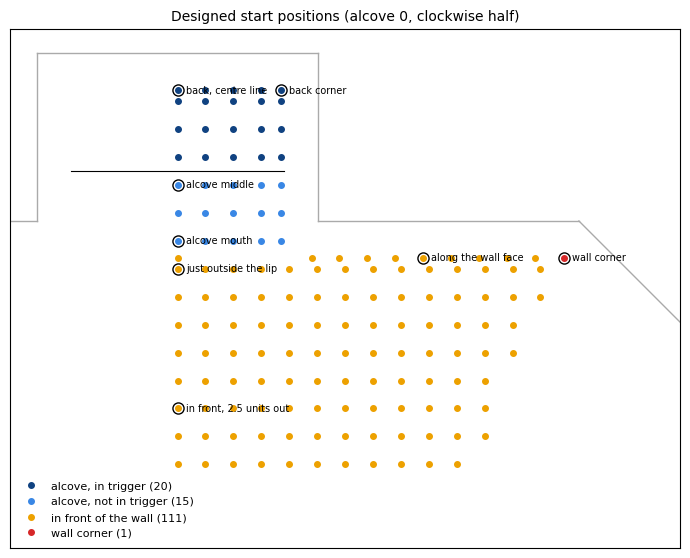

,positions
region,
in front of the wall,111
"alcove, in trigger",20
"alcove, not in trigger",15
wall corner,1


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
draw_arena(ax)
for reg, col in C_REGION.items():
    m = positions['region'] == reg
    ax.plot(positions.loc[m, 'x'], positions.loc[m, 'z'], 'o', color=col, ms=4, label=f'{reg} ({m.sum()})')
for name, i in named_idx.items():
    ax.annotate(name, positions.loc[i, ['x', 'z']], xytext=(6, -2), textcoords='offset points', fontsize=7)
    ax.plot(*positions.loc[i, ['x', 'z']], 'o', mfc='none', mec='black', ms=8)
ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.set_title('Designed start positions (alcove 0, clockwise half)', fontsize=10)
plt.tight_layout(); plt.show()
display(positions['region'].value_counts().rename('positions').to_frame())

## 2. What the rays see from each position and heading

**Motivation.** Which walls an agent sees at onset sets what it knows and how much it can infer. More walls seen means fewer places an unseen lit wall can be. The adjacent walls matter most, as they are the walls a peripheral agent can win. This section shows, for every position and heading, which walls the rays hit at onset.

**Method.** For each position, cast the 7 rays at every heading on the 0.5° grid (720 headings) and record which walls are hit (`ar.onset_sensed`). A wall counts as seen if any ray's first hit is on any part of it, including its alcove. Rays that hit the sides of the agent's own alcove count as seeing its own wall.

**Terms.**
- Walls from own alcove: 0 is the agent's own wall, +1 and -1 the adjacent walls (clockwise and anticlockwise), up to 4 opposite.
- Heading from facing centre: the heading minus the heading that points at the arena centre (degrees, positive clockwise).

**How to read the first figure.** One panel per named position. Columns are headings from facing centre (-180 to 180°), rows are walls from own alcove. A dark cell means the rays hit that wall at that heading. The line above each panel is the number of walls seen. The orange tick marks the heading chosen in section 3.

**Why it is plotted.** It shows how the view changes with heading, and how narrow some views are (for example a single adjacent wall seen over only a few degrees). It also shows which views are possible at all from each position.

**How to read the second figure.** Each dot is a position, coloured by (a) the most walls seen at any heading, (b) the share of headings that show at least one adjacent wall, and (c) the number of walls seen at the chosen heading.

**Why it is plotted.** It shows where in and around the alcove the view opens up, which is part of why the score changes with position (section 6).

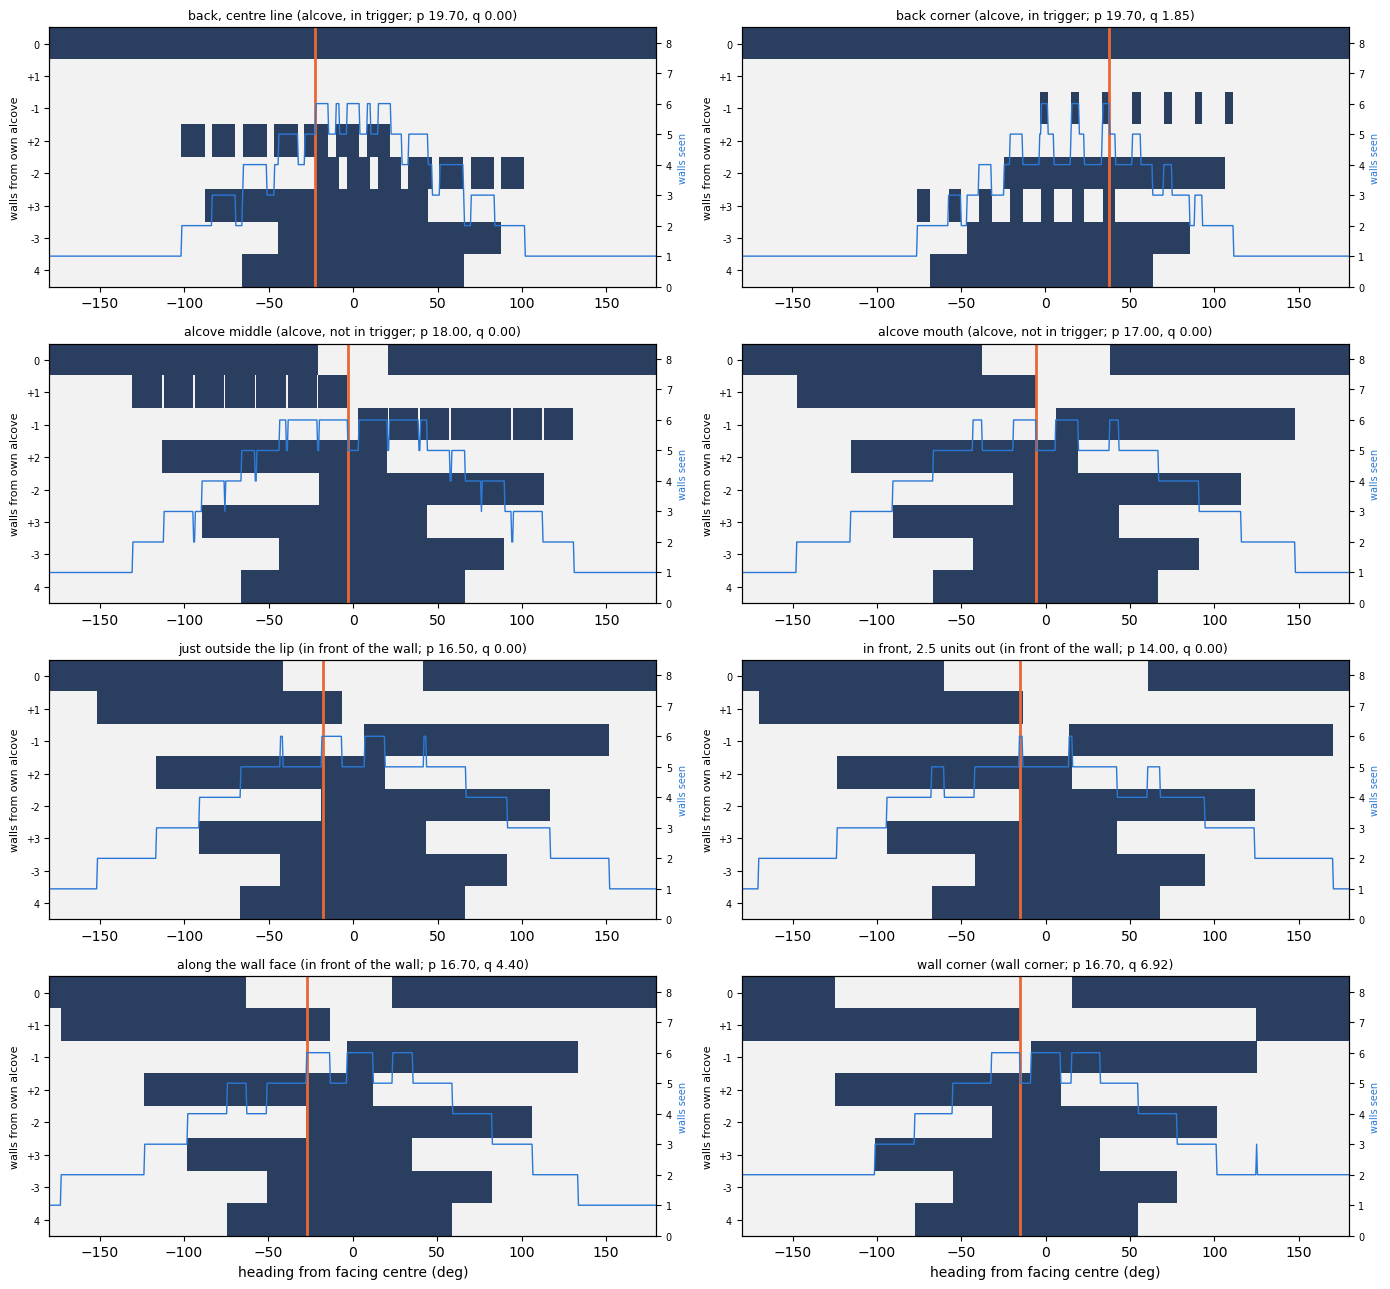

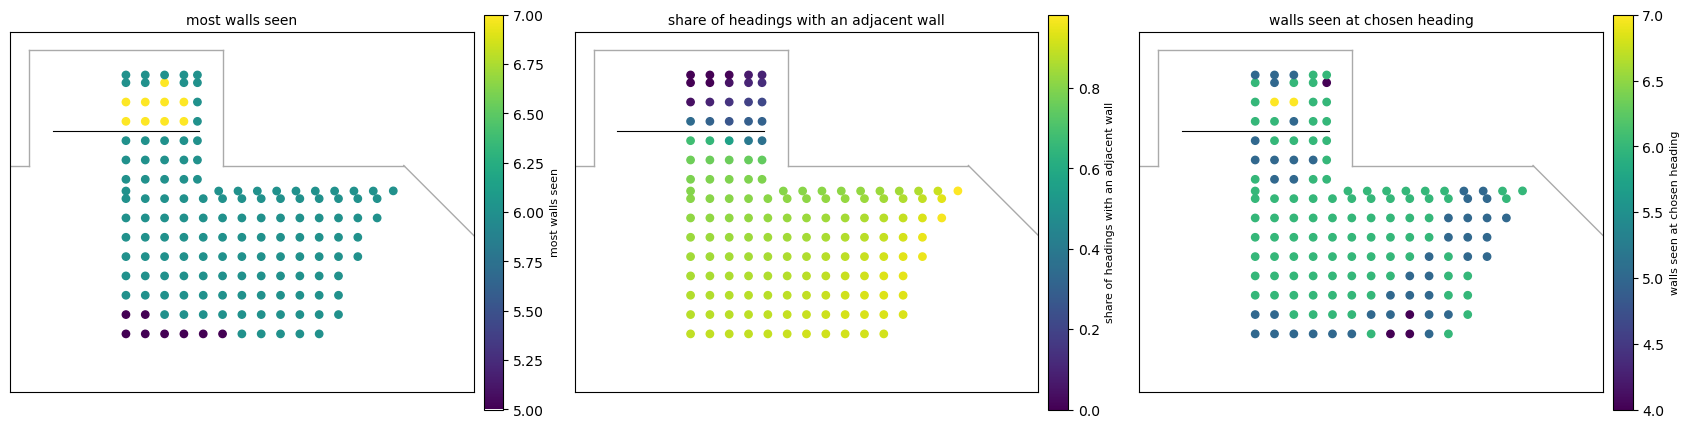

most walls seen            share of headings with an adjacent wall               walls seen at chosen heading           
                                   min median max                                     min median    max                          min median max
region                                                                                                                                         
alcove, in trigger                   6    6.0   7                                   0.000  0.096  0.339                            4    6.0   7
alcove, not in trigger               6    6.0   6                                   0.364  0.761  0.793                            5    6.0   6
in front of the wall                 5    6.0   6                                   0.800  0.872  0.968                            4    6.0   6
wall corner                          6    6.0   6                                   0.982  0.982  0.982                            6    6.0   6

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13))
order = np.argsort(REL, axis=1)
for ax, (name, i) in zip(axes.ravel(), named_idx.items()):
    o = order[i]
    img = MAP['sensed'][i][o][:, OFF_ROW].T.astype(float)
    ax.imshow(img, aspect='auto', cmap=ListedColormap(['#f2f2f2', '#2a3f5f']), interpolation='nearest',
              extent=[REL[i, o][0], REL[i, o][-1], len(OFFS) - 0.5, -0.5])
    ax.set_yticks(range(len(OFFS)), [f'{o_:+d}' if o_ not in (0, 4) else str(o_) for o_ in OFFS], fontsize=7)
    ax2 = ax.twinx()
    ax2.plot(REL[i, o], MAP['sensed'][i][o].sum(axis=1), color=C_PERIPH, lw=1)
    ax2.set_ylim(0, 8.5); ax2.set_ylabel('walls seen', fontsize=7, color=C_PERIPH); ax2.tick_params(labelsize=7)
    ax.axvline(best.loc[i, 'heading_from_centre'], color=C_ROUTE_C, lw=2)
    ax.set_title(f"{name} ({positions.loc[i, 'region']}; p {positions.loc[i, 'p']:.2f}, q {positions.loc[i, 'q']:.2f})", fontsize=9)
    ax.set_ylabel('walls from own alcove', fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel('heading from facing centre (deg)')
plt.tight_layout(); plt.show()

# summarise every position's view: most walls seen, how often an adjacent wall is seen, walls seen at the chosen heading
n_seen = MAP['sensed'].sum(axis=2)
adj_seen = MAP['sensed'][:, :, 1] | MAP['sensed'][:, :, 7]
view = pd.DataFrame({'most walls seen': n_seen.max(axis=1), 'share of headings with an adjacent wall': adj_seen.mean(axis=1),
                     'walls seen at chosen heading': best['n_sensed']})
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, col, cmap in zip(axes, view.columns, ('viridis', 'viridis', 'viridis')):
    draw_arena(ax)
    sc = ax.scatter(positions['x'], positions['z'], c=view[col], cmap=cmap, s=28)
    plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.02).set_label(col, fontsize=8)
    ax.set_title(col, fontsize=10)
plt.tight_layout(); plt.show()
display(view.join(positions['region']).groupby('region').agg(['min', 'median', 'max']).round(3))

**Interpretation.** Values are in the figures and the table above.
- From the back of the alcove the rays mostly hit the alcove's own sides. Across positions in the trigger, the share of headings that show an adjacent wall is 0 to 0.339 (median 0.096, table). Near the back centre line (4 of 20 trigger positions) no heading shows one. Off the centre line only the adjacent wall on the far side is seen (first figure, 'back corner' sees -1 only).
- From the mouth outward most headings show an adjacent wall (median share 0.761 off the trigger inside the alcove, 0.872 in front of the wall, 0.982 at the wall corner).
- Both adjacent walls are seen together at only 12 of 147 positions, all in front of the wall 13-14.5 units from the centre and 3.5-5.5 units across. Even there it is at most 0.036 of headings. Elsewhere the 7 rays (110° across) cannot take in both.
- The most walls seen at any heading is 5-7 everywhere (median 6, table). Positions differ more in which walls they see than in how many.
- In the first figure the blue line (walls seen) is drawn over the cells; read the rows from the dark cells only.

## 3. Choosing the heading

**Motivation.** The best heading depends on where the agent stands: the view changes differently with heading at each position (section 2). This section finds, for every position, the onset heading with the highest expected score per second.

**Method.**
1. For each position and each of the 720 headings, run the final rule (Δ rule with inference about both walls, plus the backpedal of section 4) for all 40 layouts and both tie-break search directions (`sp.heading_scores`).
2. Store the outcome for every Δ from 0 to 3.8 s in 0.05 s steps.
3. Score per second = expected peripheral score per trial / (expected race time + 6.545 s).
4. Keep the heading and Δ with the highest score per second (`sp.best_per_position`). Δ is chosen per position along with the heading.

**Terms.**
- `heading_from_centre`: the chosen heading minus the facing-centre heading (degrees, positive clockwise).
- `walls seen`: the walls hit at onset at the chosen heading, as offsets from own alcove.
- `near_best_deg`: how many degrees of heading come within 0.5% of the best score per second (Δ at its best for each heading). Large values mean the choice is forgiving; a few degrees means it is not.

**How to read the figure.** One panel per named position. The line is the best score per second at each heading (over Δ), against heading from facing centre. The shading behind it is the number of walls seen at that heading (darker = more). The orange line is the chosen heading. The dashed line is the central agent's score per second at the chosen heading.

**Why it is plotted.** It shows how much the heading matters at each position, and whether the best heading lines up with a change in what is seen.

**How to read the table.** One row per named position, at its chosen heading and Δ.

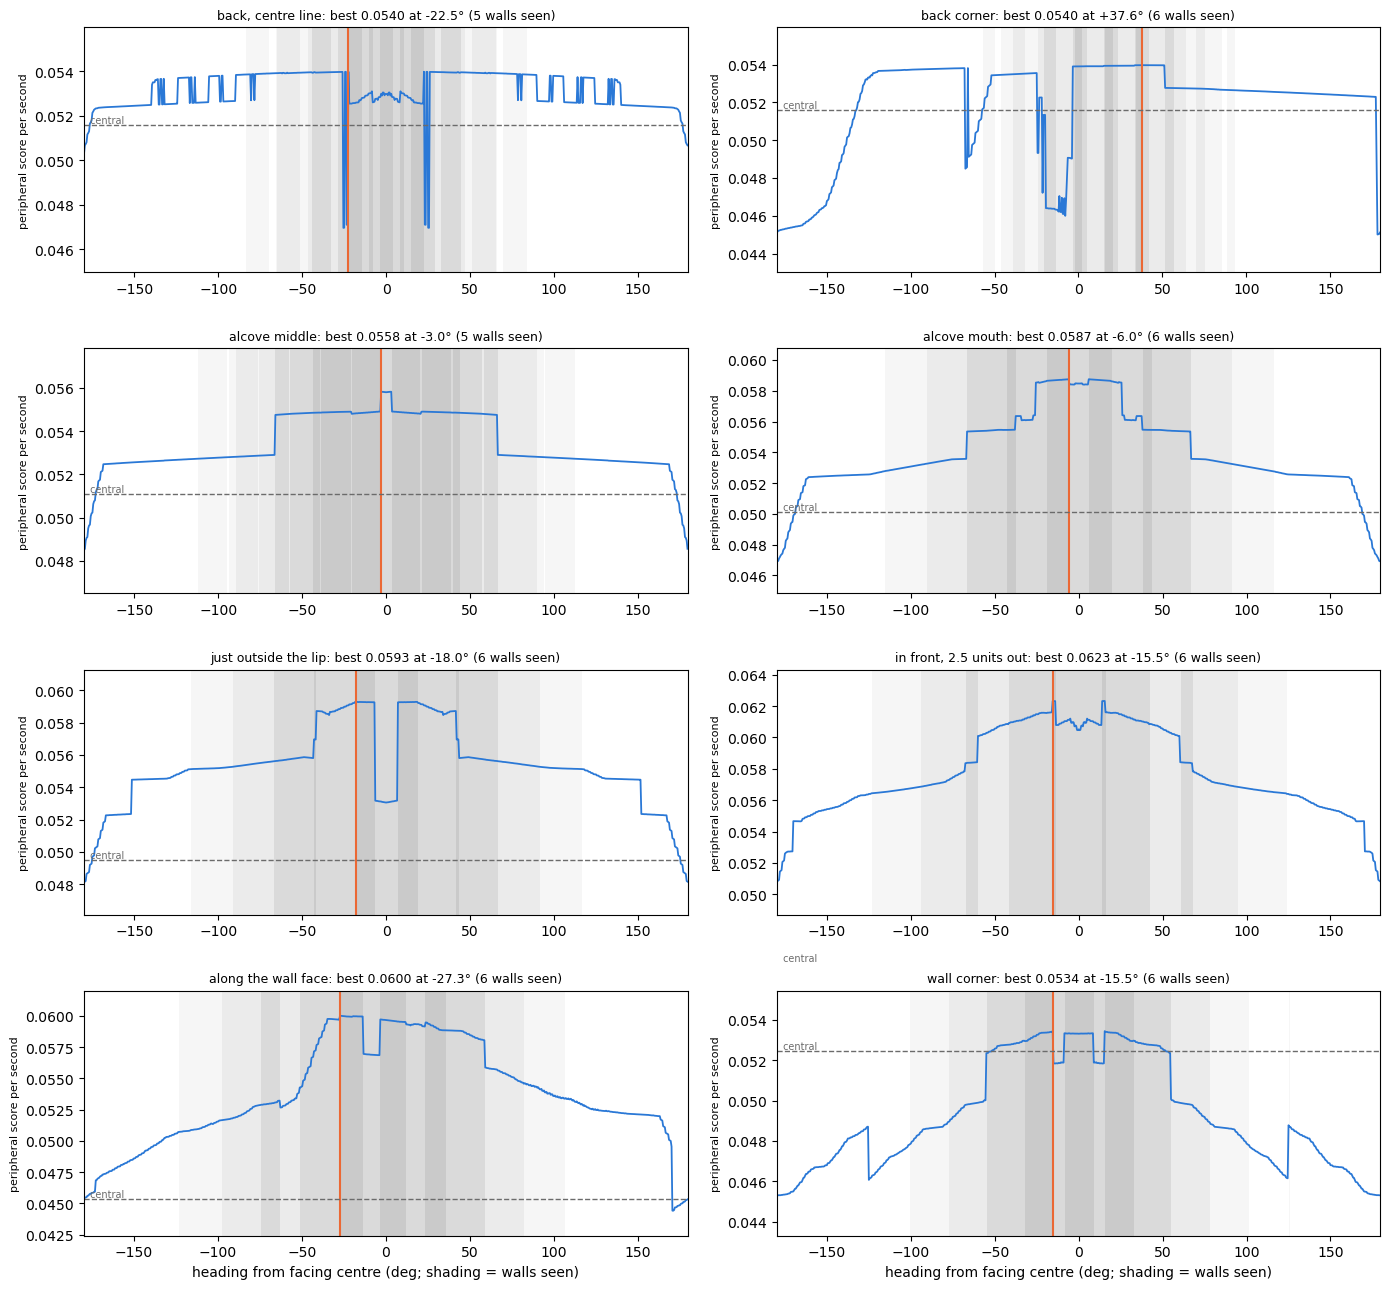

,region,heading_from_centre,delta,n_sensed,walls seen,near_best_deg,periph_score_s,central_score_s,margin
"back, centre line","alcove, in trigger",-22.5000,0.60,5,"0, +2, +3, -3, 4",154.0,0.0540,0.0516,0.0024
back corner,"alcove, in trigger",37.6352,0.20,6,"0, -1, -2, +3, -3, 4",95.0,0.0540,0.0516,0.0024
alcove middle,"alcove, not in trigger",-3.0000,1.15,5,"+2, -2, +3, -3, 4",6.5,0.0558,0.0511,0.0047
alcove mouth,"alcove, not in trigger",-6.0000,1.10,6,"+1, +2, -2, +3, -3, 4",44.5,0.0587,0.0501,0.0086
just outside the lip,in front of the wall,-18.0000,1.10,6,"+1, +2, -2, +3, -3, 4",36.0,0.0593,0.0495,0.0098
"in front, 2.5 units out",in front of the wall,-15.5000,0.80,6,"+1, +2, -2, +3, -3, 4",4.0,0.0623,0.0456,0.0167
along the wall face,in front of the wall,-27.2630,0.85,6,"+1, +2, -2, +3, -3, 4",21.5,0.0600,0.0454,0.0146
wall corner,wall corner,-15.5000,0.45,6,"+1, +2, -2, +3, -3, 4",41.5,0.0534,0.0525,0.0010


In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13))
for ax, (name, i) in zip(axes.ravel(), named_idx.items()):
    o = order[i]
    x, y = REL[i, o], PS_HEAD[i, o]
    ns = n_seen[i, o]
    lo_, hi_ = y.min(), y.max()
    ax.imshow(ns[None, :], aspect='auto', cmap='Greys', alpha=0.35, vmin=2, vmax=8,
              extent=[x[0], x[-1], lo_ - 0.002, hi_ + 0.002], interpolation='nearest')
    ax.plot(x, y, color=C_PERIPH, lw=1.3)
    ax.axvline(best.loc[i, 'heading_from_centre'], color=C_ROUTE_C, lw=1.5)
    ax.axhline(best.loc[i, 'central_score_s'], color=C_CENTRAL, ls='--', lw=1)
    ax.text(x[0] + 2, best.loc[i, 'central_score_s'], ' central', va='bottom', fontsize=7, color=C_CENTRAL)
    ax.set_ylim(lo_ - 0.002, hi_ + 0.002)
    ax.set_title(f"{name}: best {best.loc[i, 'periph_score_s']:.4f} at {best.loc[i, 'heading_from_centre']:+.1f}° "
                 f"({best.loc[i, 'n_sensed']} walls seen)", fontsize=9)
    ax.set_ylabel('peripheral score per second', fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel('heading from facing centre (deg; shading = walls seen)')
plt.tight_layout(); plt.show()

named_tab = best.loc[NAMED_I].copy()
named_tab.index = list(named_idx)
named_tab['walls seen'] = [walls_label(w) for w in named_tab['walls_sensed']]
display(named_tab[['region', 'heading_from_centre', 'delta', 'n_sensed', 'walls seen', 'near_best_deg',
                   'periph_score_s', 'central_score_s', 'margin']].round(4))

### Check: mirrored positions

**Motivation.** The map uses only the clockwise half of the sector, on the grounds that the arena is mirror-symmetric. This check confirms the model treats a mirrored position the same.

**Method.** For three named positions, mirror the position across alcove 0's centre line and mirror its chosen heading. Score the mirrored pair with the same rule, and compare.

**How to read the table.** One row per position. A difference of 0 (to rounding) means the mirror image scores the same.

In [ ]:
rows = []
for name in ('back corner', 'just outside the lip', 'along the wall face'):
    i = named_idx[name]
    p, q = positions.loc[i, ['p', 'q']]
    pm = np.array(vo.wall_frame_to_arena(p, -q, 0), float).ravel()
    hm = (-best.loc[i, 'heading']) % 360
    r = sp.heading_scores(pm, [hm], ROT, CLOSE, CT_INF)
    ps_m = r['periph_trial'][0] / (OVERHEAD + r['race_s'][0])
    j = int(np.argmin(np.abs(MAP['deltas'] - best.loc[i, 'delta'])))
    rows.append({'position': name, 'score/s here': best.loc[i, 'periph_score_s'], 'score/s mirrored': ps_m[j],
                 'difference': ps_m[j] - best.loc[i, 'periph_score_s'],
                 'same walls seen (mirrored)': bool((r['sensed'][0][sp.MIRROR_WALLS] == MAP['sensed'][i, H.tolist().index(best.loc[i, 'heading'])]).all())})
display(pd.DataFrame(rows).set_index('position').round(6))

,score/s here,score/s mirrored,difference,same walls seen (mirrored)
position,,,,
back corner,0.053972,0.053972,-0.0,True
just outside the lip,0.059289,0.059289,0.0,True
along the wall face,0.060014,0.060014,0.0,True


## 4. Backpedalling into the own trigger

**Motivation.** An agent waiting in its alcove but short of its trigger has its own wall behind it. If it can infer that its target is very probably its own wall, it does not need to turn round and look, as inference is enough and turning costs time. It can step back into the trigger without turning (user's request, 2026-10-26). The control scheme moves at full speed backwards.

**Method** (`ar._motion_kind`, `ar.blind_trace`).
1. At onset, and whenever the rays first hit a new wall, the agent works out where its target (High or Low, as chosen by the Δ rule) could be (`ar.joint_posterior`).
2. If it is in its own alcove, not on its trigger, and the probability that its target is its own wall is 0.8 or more, it moves straight back into the trigger at 10 units/s, keeping its heading.
3. If its own wall is lit (as the target, or as the other lit wall), entering the trigger ends the trial there.
4. If its own wall is unlit (the gamble lost), the agent learns this on reaching the trigger and the rule decides again from there.
5. Otherwise it moves as before (turns onto its path to a seen target, or searches).

An agent that starts on its own trigger never backpedals. The trial did not end at once, so it has already experienced that its own wall is unlit.

**Choices.** The 0.8 threshold is an arbitrary value picked for now (user's choice). The backpedal applies only inside the agent's own alcove (user's specification). Every other motion still turns to face its path.

**How to read the table.** For each named position, at its chosen heading and Δ: the share of trials (weighted by layout) with a backpedal that ends the trial at the own wall, and with a backpedal into an unlit trigger. Positions on their trigger, or outside the alcove, never backpedal.

**How to read the figure.** One example at a named position inside the alcove, at its chosen heading and Δ. Rays at onset are thin black lines. The backpedal is purple, searches are dashed and other routes solid. The orange line is the agent's heading. The title gives the outcome.

,region,backpedal ends at own wall,backpedal into an unlit trigger
"back, centre line","alcove, in trigger",0.0,0.0
back corner,"alcove, in trigger",0.0,0.0
alcove middle,"alcove, not in trigger",0.21875,0.0
alcove mouth,"alcove, not in trigger",0.09375,0.0
just outside the lip,in front of the wall,0.0,0.0
"in front, 2.5 units out",in front of the wall,0.0,0.0
along the wall face,in front of the wall,0.0,0.0
wall corner,wall corner,0.0,0.0


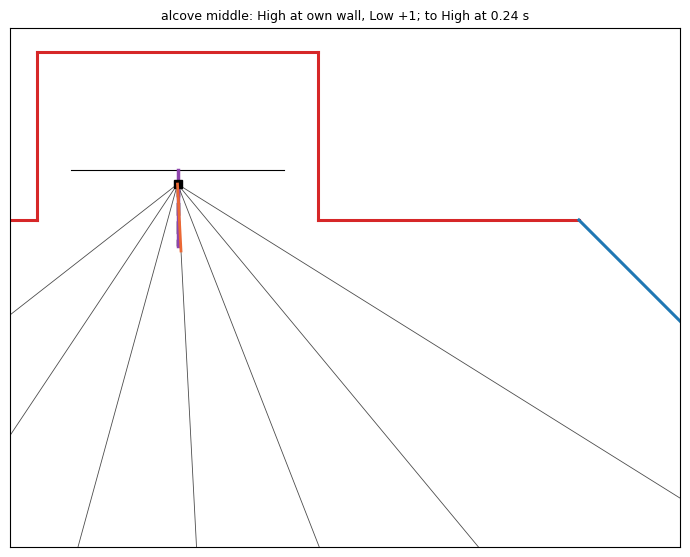

In [ ]:
# find, at each named position, how often the agent backpedals, and how often the own wall turns out unlit
lay = ar.layout_table()
rows, example = {}, None
for name, i in named_idx.items():
    p = positions.loc[i, ['x', 'z']].to_numpy(float)
    h, d = best.loc[i, 'heading'], best.loc[i, 'delta']
    won, lost = 0.0, 0.0
    for hi, lo, pr in zip(lay['high'], lay['low'], lay['prob']):
        for dr in (1, -1):
            r = ar.delta2_route(p, h, int(hi), int(lo), dr, d, ROT, CLOSE)
            if 'backpedal' not in r['kinds']:
                continue
            # a backpedal that is the last motion ends the trial at the own wall
            if r['kinds'][-1] == 'backpedal':
                won += pr / 2
                if example is None and hi == 0:
                    example = (name, i, int(hi), int(lo), r)
            else:
                lost += pr / 2
    rows[name] = {'region': positions.loc[i, 'region'], 'backpedal ends at own wall': won,
                  'backpedal into an unlit trigger': lost}
display(pd.DataFrame(rows).T)

if example is None:
    print('no backpedal at the named positions')
else:
    name, i, hi, lo, r = example
    p = positions.loc[i, ['x', 'z']].to_numpy(float)
    fig, ax = plt.subplots(figsize=(7, 6))
    draw_arena(ax, hi, lo)
    draw_rays(ax, p, best.loc[i, 'heading'])
    for (state, s0, e, t0, is_search), kind in zip(r['segments'], r['kinds']):
        xy = np.array([state(t)[0] for t in np.linspace(s0, e, 120)])
        ax.plot(xy[:, 0], xy[:, 1], color='#8e44ad' if kind == 'backpedal' else 'black',
                ls='--' if kind == 'search' else '-', lw=2.5)
    ax.plot(*p, 'ks', ms=6)
    arrow(ax, p, best.loc[i, 'heading'], length=1.2, color=C_ROUTE_C, lw=2)
    ax.set_title(f"{name}: High at own wall, Low {int(ar.signed_offset(lo)):+d}; "
                 f"to {'Low' if r['go_low'] else 'High'} at {r['time']:.2f} s", fontsize=9)
    plt.tight_layout(); plt.show()

## 5. The score map

**Motivation.** The main question: where should a peripheral player wait, and how does that compare with where the RL agents waited, and with playing central?

**Method.** For each position, take the chosen heading and Δ (section 3). Compare with:
- the logged peripheral positions and headings (2,376 agent-trials from six 260929 models), at Δ 1.05 s and at their own best Δ, rebuilt with the backpedal rule;
- central vs central play (both agents at the centre, going High).

**Terms.**
- `periph_score_s`, `central_score_s`: expected score per second for the peripheral agent and its central opponent.
- `margin`: peripheral minus central score per second (0 = level; central vs central play has margin 0).

**How to read the figure.** Each dot is a position, coloured by (a) the peripheral agent's best score per second, (b) the margin over its central opponent (blue = peripheral ahead, red = behind, white = level), and (c) the best score per second at Δ fixed at 1.05 s. Short black lines show the chosen heading at each position. The colour bar of (a) and (c) is marked at the central-vs-central score.

**Why it is plotted.** It shows where waiting pays, and whether the answer depends on tuning Δ for each position.

**How to read the tables.** The first gives the best position in each region, with the logged positions and central play for comparison. The second gives every named position.

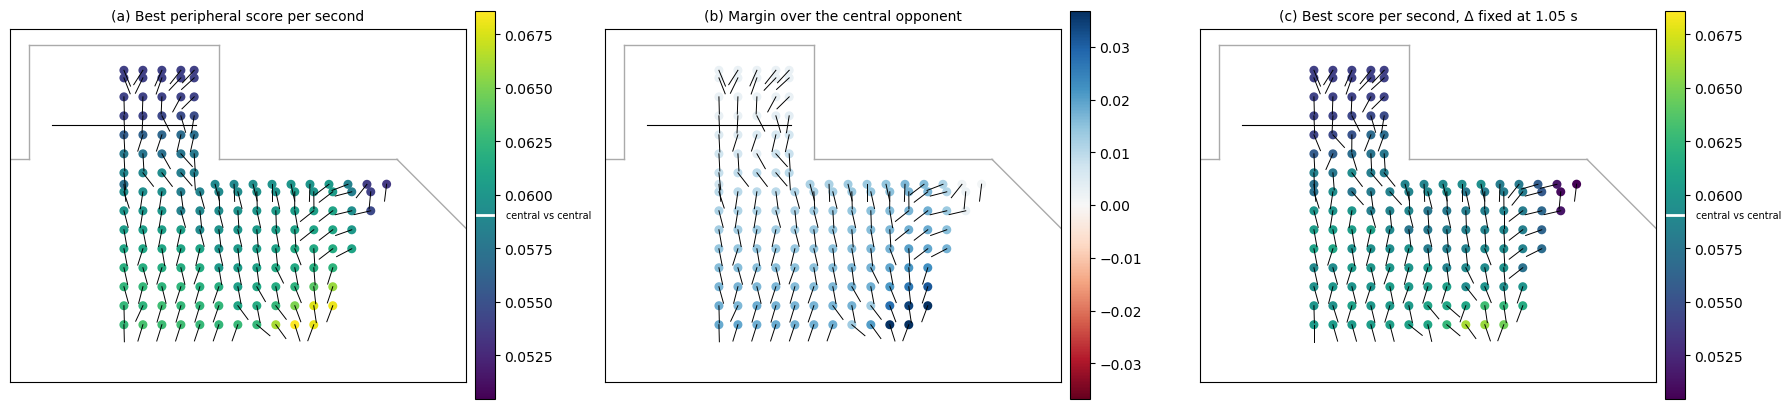

,p,q,heading_from_centre,delta,n_sensed,periph_score_s,central_score_s,margin
region,,,,,,,,
"alcove, in trigger",18.5000,1.8500,3.2894,0.25,6.0,0.0547,0.0510,0.0037
"alcove, not in trigger",17.0000,1.0000,-40.8665,1.05,5.0,0.0592,0.0493,0.0099
in front of the wall,13.0000,4.5000,-36.5935,0.25,5.0,0.0686,0.0324,0.0362
wall corner,16.7008,6.9177,-15.5000,0.45,6.0,0.0534,0.0525,0.0010
"logged positions, Δ 1.05 s",NaN,NaN,NaN,1.05,NaN,0.0527,0.0531,-0.0004
"logged positions, best Δ",NaN,NaN,NaN,1.05,NaN,0.0527,0.0531,-0.0004
central vs central,NaN,NaN,NaN,NaN,NaN,0.0591,0.0591,0.0000


,region,periph_score_s,central_score_s,margin,delta,heading_from_centre,periph_score_s (Δ 1.05),margin (Δ 1.05)
"back, centre line","alcove, in trigger",0.0540,0.0516,0.0024,0.60,-22.5000,0.0540,0.0024
back corner,"alcove, in trigger",0.0540,0.0516,0.0024,0.20,37.6352,0.0540,0.0024
alcove middle,"alcove, not in trigger",0.0558,0.0511,0.0047,1.15,-3.0000,0.0542,0.0024
alcove mouth,"alcove, not in trigger",0.0587,0.0501,0.0086,1.10,-6.0000,0.0585,0.0086
just outside the lip,in front of the wall,0.0593,0.0495,0.0098,1.10,-18.0000,0.0572,0.0075
"in front, 2.5 units out",in front of the wall,0.0623,0.0456,0.0167,0.80,-15.5000,0.0596,0.0069
along the wall face,in front of the wall,0.0600,0.0454,0.0146,0.85,-27.2630,0.0595,0.0129
wall corner,wall corner,0.0534,0.0525,0.0010,0.45,-15.5000,0.0505,-0.0091


In [ ]:
ref = ar.central_reference(OVERHEAD, central_t=CT_INF)['score_s']
pooled = races.assign(group=0, prob=races['prob'] / races['prob'].sum())
sw = pd.DataFrame([ar.summarise(pooled, OVERHEAD, 'delta2', d, CT_INF).iloc[0].to_dict() | {'delta': d} for d in MAP['deltas']])
logged_fix = sw.loc[np.isclose(sw['delta'], D_FIX)].iloc[0]
logged_best = sw.loc[sw['periph_score_s'].idxmax()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
vmin, vmax = min(best['periph_score_s'].min(), best_fix['periph_score_s'].min()), max(best['periph_score_s'].max(), ref)
for ax, tab, col, title in ((axes[0], best, 'periph_score_s', '(a) Best peripheral score per second'),
                            (axes[1], best, 'margin', '(b) Margin over the central opponent'),
                            (axes[2], best_fix, 'periph_score_s', '(c) Best score per second, Δ fixed at 1.05 s')):
    draw_arena(ax)
    if col == 'margin':
        lim = np.abs(tab[col]).max()
        sc = ax.scatter(tab['x'], tab['z'], c=tab[col], cmap='RdBu', vmin=-lim, vmax=lim, s=30)
    else:
        sc = ax.scatter(tab['x'], tab['z'], c=tab[col], cmap='viridis', vmin=vmin, vmax=vmax, s=30)
    cb = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.02)
    if col != 'margin':
        cb.ax.axhline(ref, color='white', lw=2); cb.ax.text(1.6, ref, 'central vs central', fontsize=7, va='center',
                                                            transform=cb.ax.get_yaxis_transform())
    for _, r_ in tab.iterrows():
        arrow(ax, (r_['x'], r_['z']), r_['heading'], length=0.45, color='black', lw=0.7)
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

# compare the best position in each region with the logged positions and central play
top = best.loc[best.groupby('region')['periph_score_s'].idxmax(),
               ['region', 'p', 'q', 'heading_from_centre', 'delta', 'n_sensed', 'periph_score_s', 'central_score_s', 'margin']]
top = top.set_index('region')
top.loc['logged positions, Δ 1.05 s'] = [np.nan, np.nan, np.nan, D_FIX, np.nan, logged_fix['periph_score_s'],
                                         logged_fix['central_score_s'], logged_fix['periph_score_s'] - logged_fix['central_score_s']]
top.loc['logged positions, best Δ'] = [np.nan, np.nan, np.nan, logged_best['delta'], np.nan, logged_best['periph_score_s'],
                                       logged_best['central_score_s'], logged_best['periph_score_s'] - logged_best['central_score_s']]
top.loc['central vs central'] = [np.nan, np.nan, np.nan, np.nan, np.nan, ref, ref, 0.0]
display(top.round(4))
display(named_tab[['region', 'periph_score_s', 'central_score_s', 'margin', 'delta', 'heading_from_centre']].join(
    best_fix.loc[NAMED_I, ['periph_score_s', 'margin']].set_axis(list(named_idx)).add_suffix(' (Δ 1.05)')).round(4))

## 6. Why the score changes between positions

**Motivation.** Section 5 shows where waiting pays. This section shows why, by splitting each named position's trials by where High is and who wins them, beside what the agent sees at onset.

**Method.** For each named position, at its chosen heading and Δ, evaluate every layout and both tie-break directions (`sp.position_races`, `ar.evaluate`). Group the trials by where High is, relative to the agent's own wall.

**Terms.**
- `instant`: the agent overlaps a lit wall's trigger at onset and wins it at once.
- `High own wall`, `High adjacent`, `High 2+ walls away`: where High is, for the other trials.
- Shares are of all trials, so each column of bars sums to 1.

**How to read the figure.** One bar per named position. Each bar splits all trials into peripheral wins at High (dark blue), peripheral wins at Low (light blue) and central wins (grey). The label above each bar is the number of walls seen at onset at the chosen heading.

**How to read the table.** One row per named position and group: the share of trials, the peripheral agent's wins at High and Low, the central agent's wins, and each agent's contribution to score per trial.

**Why it is plotted.** It shows what each position gains and gives up. A position inside the trigger wins its own wall instantly. A position further out sees more and is nearer the adjacent walls, but must travel to its own wall.

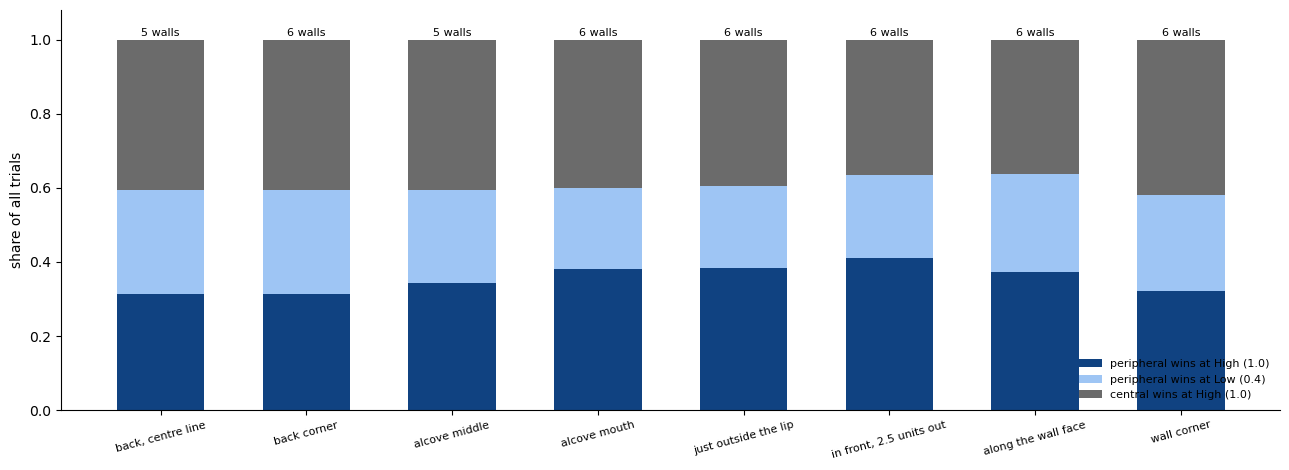

share of trials  peripheral wins at High  peripheral wins at Low  central wins  peripheral score/trial  central score/trial
position                group                                                                                                                                          
back, centre line       High 2+ walls away            0.562                    0.000                   0.156         0.406                   0.062                0.406
                        High adjacent                 0.188                    0.188                   0.000         0.000                   0.188                0.000
                        instant                       0.250                    0.125                   0.125         0.000                   0.175                0.000
back corner             High 2+ walls away            0.562                    0.000                   0.156         0.406                   0.062                0.406
                        High adjacent                 0.188                    0.188                   0.000         0.000                   0.188                0.000
                        instant                       0.250                    0.125                   0.125         0.000                   0.175                0.000
alcove middle           High 2+ walls away            0.625                    0.000                   0.219         0.406                   0.088                0.406
                        High adjacent                 0.250                    0.219                   0.031         0.000                   0.231                0.000
                        High own wall                 0.125                    0.125                   0.000         0.000                   0.125                0.000
alcove mouth            High 2+ walls away            0.625                    0.005                   0.220         0.400                   0.093                0.400
                        High adjacent                 0.250                    0.250                   0.000         0.000                   0.250                0.000
                        High own wall                 0.125                    0.125                   0.000         0.000                   0.125                0.000
just outside the lip    High 2+ walls away            0.625                    0.010                   0.221         0.395                   0.098                0.395
                        High adjacent                 0.250                    0.250                   0.000         0.000                   0.250                0.000
                        High own wall                 0.125                    0.125                   0.000         0.000                   0.125                0.000
in front, 2.5 units out High 2+ walls away            0.625                    0.036                   0.223         0.366                   0.125                0.366
                        High adjacent                 0.250                    0.250                   0.000         0.000                   0.250                0.000
                        High own wall                 0.125                    0.125                   0.000         0.000                   0.125                0.000
along the wall face     High 2+ walls away            0.625                    0.029                   0.234         0.362                   0.123                0.362
                        High adjacent                 0.250                    0.219                   0.031         0.000                   0.231                0.000
                        High own wall                 0.125                    0.125                   0.000         0.000                   0.125                0.000
wall corner             High 2+ walls away            0.625                    0.038                   0.213         0.374                   0.123                0.374
            

In [ ]:
def outcome_groups(i):
    """ Return trial shares and outcomes by where High is, for a position at its chosen heading and delta. """

    p = positions.loc[i, ['x', 'z']].to_numpy(float)
    rc = sp.position_races(p, best.loc[i, 'heading'], ROT, CLOSE)
    ev = ar.evaluate(rc, 'delta2', best.loc[i, 'delta'], CT_INF)
    w = rc['prob'].to_numpy()
    off = np.abs(ar.signed_offset(rc['high'].to_numpy()))
    inst = (rc['t_high'] == 0) | (rc['t_low'] == 0)
    grp = np.where(inst, 'instant', np.where(off == 0, 'High own wall', np.where(off == 1, 'High adjacent', 'High 2+ walls away')))
    win = ev['periph_win'].to_numpy()
    high_win = win * ~ev['go_low'].to_numpy()
    df = pd.DataFrame({'group': grp, 'share of trials': w, 'peripheral wins at High': w * high_win,
                       'peripheral wins at Low': w * (win - high_win), 'central wins': w * (1 - win),
                       'peripheral score/trial': w * ev['periph_score'], 'central score/trial': w * ev['central_score']})
    return df.groupby('group').sum()


groups = {name: outcome_groups(i) for name, i in named_idx.items()}
fig, ax = plt.subplots(figsize=(13, 4.8))
xg = np.arange(len(groups))
tot = pd.DataFrame({n: g.sum() for n, g in groups.items()}).T
ax.bar(xg, tot['peripheral wins at High'], color='#104281', width=0.6, label='peripheral wins at High (1.0)')
ax.bar(xg, tot['peripheral wins at Low'], bottom=tot['peripheral wins at High'], color='#9ec5f4', width=0.6,
       label='peripheral wins at Low (0.4)')
ax.bar(xg, tot['central wins'], bottom=tot['peripheral wins at High'] + tot['peripheral wins at Low'], color=C_CENTRAL,
       width=0.6, label='central wins at High (1.0)')
for x_, name in zip(xg, groups):
    ax.text(x_, 1.01, f"{best.loc[named_idx[name], 'n_sensed']} walls", ha='center', fontsize=8)
ax.set_xticks(xg, list(groups), fontsize=8, rotation=15)
ax.set_ylim(0, 1.08); ax.set_ylabel('share of all trials'); ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
display(pd.concat(groups, names=['position']).round(3))

## 7. Interpretation and limits

**Interpretation.** Values are in the tables of sections 3-6.
- Every designed position, at its best heading and Δ, out-scores its central opponent (margin +0.0010 to +0.0368; none below 0). The logged positions trail (0.0527 against 0.0531, margin -0.0004; section 5, first table).
- Positions in the trigger score 0.0540-0.0547 (margin +0.0024 to +0.0037). This is above the logged positions mainly because every designed trigger position wins a lit own wall at once. Instant wins are 0.250 of trials here (section 6) against 0.233 for the logged positions (`geometric_model_assembly.ipynb`, section 8), since 0.934 of logged starts are on the trigger. Heading hardly matters in the trigger: headings within 0.5% of the best span 38.5-157° (median 119°).
- Inside the alcove but off the trigger, scores are 0.0558-0.0592. The backpedal is used here. At the alcove middle 0.219 of trials end with a backpedal to the own wall, and at the mouth 0.094 (section 4). No backpedal at the named positions entered an unlit trigger.
- In front of the wall, the score rises steadily toward the centre. The best position in each row goes from 0.0603 at the wall face to 0.0686 at 13 units from the centre, the grid's inner edge. The best position overall is 13 units out and 4.5 across, toward the line shared with the next wall: 0.0686 against 0.0324, above central vs central (0.0591). As this is on the grid's edge, the true best position is probably further in, where the player is no longer waiting at a wall.
- Moving out of the alcove gives up the instant wins (0.250 of trials in the trigger, none outside) but gains elsewhere (section 6). At 2.5 units out the agent wins every adjacent-High layout (0.250 of trials, against 0.188 from the alcove back) and every own-wall High (0.125). It takes more Lows when High is two or more walls away (0.223 against 0.156), and the central agent wins fewer trials (0.366 against 0.406).
- The wall corner is the weakest position outside the alcove: 0.0534, margin +0.0010. It is far from both neighbouring triggers, so the central agent wins some adjacent-High layouts (0.044 of trials).
- Heading matters more outside the trigger. Headings within 0.5% of the best span a median of 13° off the trigger in the alcove and 14° in front of the wall, and only 4° at 2.5 units out (section 3 table).
- Choosing Δ per position adds to the score in front of the wall. At Δ fixed at 1.05 s, 2.5 units out scores 0.0596 instead of 0.0623, and four positions (three in front, and the wall corner) fall behind their opponent (section 5).

**Limits.**
- **Rays, not human vision.** The view from each position, and so the best heading, is for the RL agents' 7 rays. A human sees a continuous field of view, so narrow views that 7 rays find only at a few headings would be open to a human over many. This should be rerun with a human field of view before applying it to human players.
- **The backpedal threshold of 0.8 is arbitrary.** A lower threshold would backpedal more often and lose the gamble more often.
- **Δ is tuned per position.** Results at a fixed Δ of 1.05 s are shown beside them (section 5).
- **The positions are a 0.5-unit grid,** and the best position may lie between grid points. The grid stops 13 units from the centre, where the best scores are, so it does not find the overall best position.
- **The central opponent is fixed.** It starts at the exact centre, always goes High, ignores the peripheral agent and cannot be blocked. A peripheral player standing closer to the centre would compete more directly, and the central agent's best play against it may differ.